In [44]:
import pandas as pd
import numpy as np
import sqlite3
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [45]:
connection=sqlite3.connect(r'C:\Users\sk021\Desktop\Project 2\Data\inventory2.db')

In [46]:
tables=pd.read_sql_query("select name from sqlite_master where type = 'table'  ",connection)

In [47]:
tables

,name
0,purchases
1,purchase_prices
2,vendor_invoice
3,begin_inventory
4,end_inventory


In [48]:
for table in tables['name']:
    print(f"Table name",table)
    df=pd.read_sql_query(f"select * from {table} limit 5",connection)
    display(df)

Table name purchases


,InventoryId,Store,Brand,Description,Size,VendorNumber,VendorName,PONumber,PODate,ReceivingDate,InvoiceDate,PayDate,PurchasePrice,Quantity,Dollars,Classification
0,69_MOUNTMEND_8412,69,8412,Tequila Ocho Plata Fresno,750mL,105,ALTAMAR BRANDS LLC,8124,2023-12-21,2024-01-02,2024-01-04,2024-02-16,35.71,6,214.26,1
1,30_CULCHETH_5255,30,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,4,37.40,1
2,34_PITMERDEN_5215,34,5215,TGI Fridays Long Island Iced,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-02,2024-01-07,2024-02-21,9.41,5,47.05,1
3,1_HARDERSFIELD_5255,1,5255,TGI Fridays Ultimte Mudslide,1.75L,4466,AMERICAN VINTAGE BEVERAGE,8137,2023-12-22,2024-01-01,2024-01-07,2024-02-21,9.35,6,56.10,1
4,76_DONCASTER_2034,76,2034,Glendalough Double Barrel,750mL,388,ATLANTIC IMPORTING COMPANY,8169,2023-12-24,2024-01-02,2024-01-09,2024-02-16,21.32,5,106.60,1


Table name purchase_prices


,Brand,Description,Price,Size,Volume,Classification,PurchasePrice,VendorNumber,VendorName
0,58,Gekkeikan Black & Gold Sake,12.99,750mL,750,1,9.28,8320,SHAW ROSS INT L IMP LTD
1,62,Herradura Silver Tequila,36.99,750mL,750,1,28.67,1128,BROWN-FORMAN CORP
2,63,Herradura Reposado Tequila,38.99,750mL,750,1,30.46,1128,BROWN-FORMAN CORP
3,72,No. 3 London Dry Gin,34.99,750mL,750,1,26.11,9165,ULTRA BEVERAGE COMPANY LLP
4,75,Three Olives Tomato Vodka,14.99,750mL,750,1,10.94,7245,PROXIMO SPIRITS INC.


Table name vendor_invoice


,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


Table name begin_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,startDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,8,12.99,2024-01-01
1,1_HARDERSFIELD_60,1,HARDERSFIELD,60,Canadian Club 1858 VAP,750mL,7,10.99,2024-01-01
2,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,6,36.99,2024-01-01
3,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,3,38.99,2024-01-01
4,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,6,34.99,2024-01-01


Table name end_inventory


,InventoryId,Store,City,Brand,Description,Size,onHand,Price,endDate
0,1_HARDERSFIELD_58,1,HARDERSFIELD,58,Gekkeikan Black & Gold Sake,750mL,11,12.99,2024-12-31
1,1_HARDERSFIELD_62,1,HARDERSFIELD,62,Herradura Silver Tequila,750mL,7,36.99,2024-12-31
2,1_HARDERSFIELD_63,1,HARDERSFIELD,63,Herradura Reposado Tequila,750mL,7,38.99,2024-12-31
3,1_HARDERSFIELD_72,1,HARDERSFIELD,72,No. 3 London Dry Gin,750mL,4,34.99,2024-12-31
4,1_HARDERSFIELD_75,1,HARDERSFIELD,75,Three Olives Tomato Vodka,750mL,7,14.99,2024-12-31


# For fright cost prediction we only need vendor_invoice table as it contain fright,cost and quantity

In [49]:
vendor_invlice=pd.read_sql_query("select * from vendor_invoice",connection)

In [50]:
vendor_invlice

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None
...,...,...,...,...,...,...,...,...,...,...
5538,9622,WEIN BAUER INC,2025-01-06,13626,2024-12-21,2025-02-10,90,1563.00,8.60,None
5539,9625,WESTERN SPIRITS BEVERAGE CO,2025-01-10,13661,2024-12-23,2025-02-18,4617,37300.48,186.50,None
5540,3664,WILLIAM GRANT & SONS INC,2025-01-02,13643,2024-12-22,2025-02-04,9848,202815.78,932.95,None
5541,9815,WINE GROUP INC,2025-01-03,13602,2024-12-20,2025-02-08,24747,149007.56,819.54,None


In [51]:
vendor_invoice_df=vendor_invlice[['Dollars','Quantity','Freight']]

In [52]:
vendor_invoice_df

,Dollars,Quantity,Freight
0,214.26,6,3.47
1,140.55,15,8.57
2,106.60,5,4.61
3,137483.78,10100,2935.20
4,15527.25,1935,429.20
...,...,...,...
5538,1563.00,90,8.60
5539,37300.48,4617,186.50
5540,202815.78,9848,932.95
5541,149007.56,24747,819.54


In [53]:
vendor_invoice_df.corr()

,Dollars,Quantity,Freight
Dollars,1.000000,0.963831,0.985141
Quantity,0.963831,1.000000,0.946550
Freight,0.985141,0.946550,1.000000


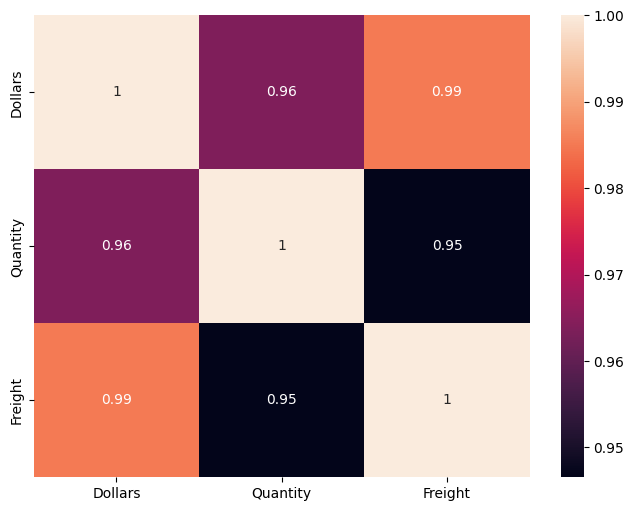

In [54]:
plt.figure(figsize=(8,6))
sns.heatmap(vendor_invoice_df[['Dollars','Quantity','Freight']].corr(),annot=True,color="Blue")
plt.show()

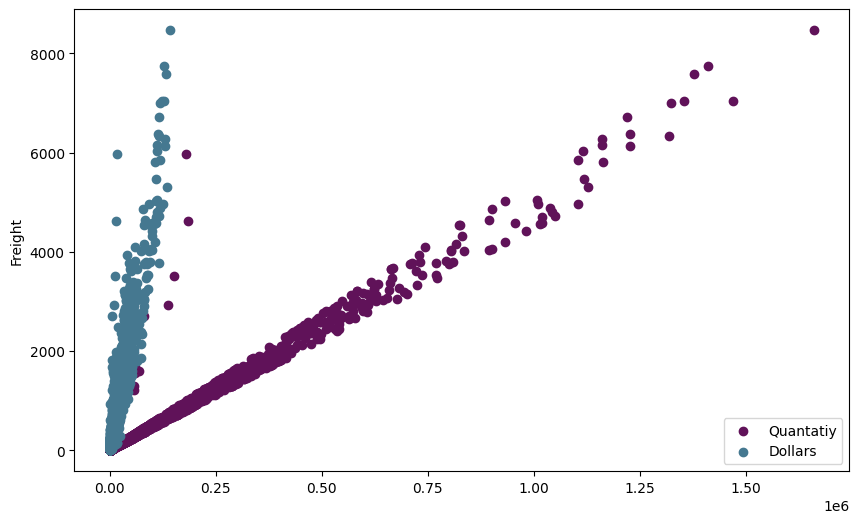

In [55]:
plt.figure(figsize=(10,6))
plt.scatter(vendor_invoice_df['Dollars'],vendor_invoice_df['Freight'],color='#601259')
plt.scatter(vendor_invlice['Quantity'],vendor_invoice_df['Freight'],color='#457890')
plt.legend(['Quantatiy','Dollars'])
plt.ylabel('Freight')
plt.show()

In [56]:
vendor_invoice_df['Freight_per_unit']=vendor_invoice_df['Freight'] / vendor_invoice_df['Quantity']

C:\Users\sk021\AppData\Local\Temp\ipykernel_12524\218672149.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  vendor_invoice_df['Freight_per_unit']=vendor_invoice_df['Freight'] / vendor_invoice_df['Quantity']


In [57]:
vendor_invoice_df

,Dollars,Quantity,Freight,Freight_per_unit
0,214.26,6,3.47,0.578333
1,140.55,15,8.57,0.571333
2,106.60,5,4.61,0.922000
3,137483.78,10100,2935.20,0.290614
4,15527.25,1935,429.20,0.221809
...,...,...,...,...
5538,1563.00,90,8.60,0.095556
5539,37300.48,4617,186.50,0.040394
5540,202815.78,9848,932.95,0.094735
5541,149007.56,24747,819.54,0.033117


In [58]:
low_quantity=vendor_invoice_df['Quantity'].quantile(0.25)
low_quantity

np.float64(83.0)

In [59]:
high_quantity=vendor_invoice_df['Quantity'].quantile(0.75)
high_quantity

np.float64(5100.5)

In [60]:
vendor_invoice_df.loc[vendor_invoice_df['Quantity']<low_quantity,'Freight_per_unit'].mean()

np.float64(0.09489854253138316)

In [61]:
vendor_invoice_df.loc[vendor_invoice_df['Quantity']<high_quantity,'Freight_per_unit'].mean()

np.float64(0.07463123347873155)

### Training Machine Learning Model to predict Freight cost

In [62]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error,mean_squared_error,mean_absolute_error,r2_score

In [63]:
X=vendor_invoice_df[['Dollars']]
Y=vendor_invoice_df[['Freight']]

In [64]:
X_train, X_test ,y_train, y_test=train_test_split(X,Y,test_size=0.2,random_state=42)

In [84]:
X_train

,Dollars
2609,264.24
5527,342.48
5321,572.40
3805,68821.14
1215,604197.73
...,...
3772,2618.27
5191,74386.98
5226,36.96
5390,644.00


In [65]:
lin_model=LinearRegression()
lin_model.fit(X_train,y_train)

LinearRegression()

In [66]:
prediction=lin_model.predict(X_test)

In [67]:
print(f"MAE : {mean_absolute_error(y_test,prediction)*100 :.2f}")
print(f"RMSE : {root_mean_squared_error(y_test,prediction)*100 :.2f}")
print(f"MSE : {mean_squared_error(y_test,prediction)*100 :.2f}")
print(f"R2 Score : {r2_score(y_test,prediction)*100 :.2f}")

MAE : 2410.60
RMSE : 12472.10
MSE : 1555531.84
R2 Score : 96.99


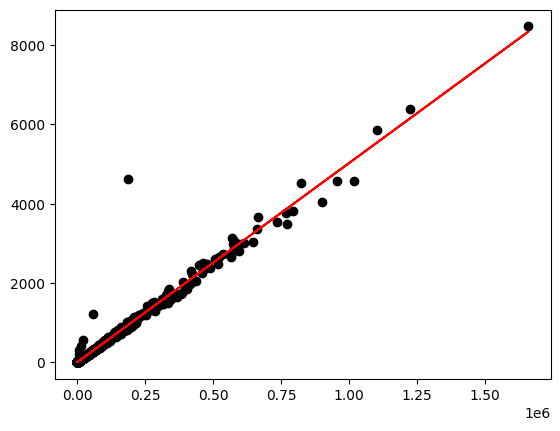

In [68]:
plt.scatter(X_test['Dollars'],y_test,color='Black')
plt.plot(X_test['Dollars'],prediction,color='Red')
plt.show()

### Infrencing

In [69]:
input_data={
    'Dollars': [137483.78],
}
df=pd.DataFrame(input_data)

In [70]:
freight=lin_model.predict(df)
print(f"Freight : {freight[0][0]}")

Freight : 694.5126685961615


In [71]:
from sklearn.svm import SVR
from sklearn.metrics import accuracy_score

In [72]:
svm_model=SVR(kernel='rbf',C=15.0,        
gamma='scale',  
epsilon=0.1,    
coef0=0.0)

In [73]:
svm_model.fit(X_train[['Dollars']],y_train)

C:\Users\sk021\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


SVR(C=15.0)

In [74]:
prediction=svm_model.predict(X_test[['Dollars']])

C:\Users\sk021\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but SVR was fitted with feature names
  warnings.warn(


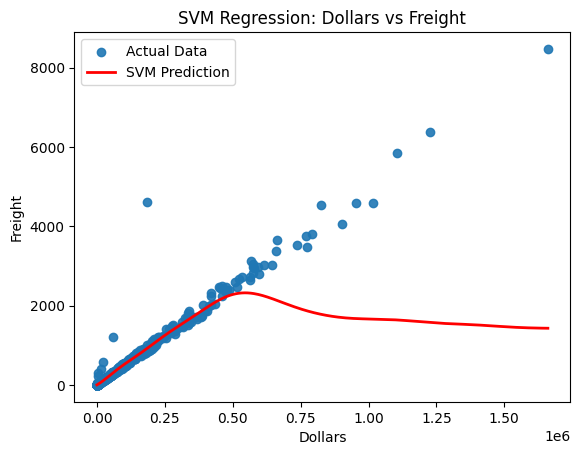

In [75]:
plt.scatter(X_test['Dollars'], y_test, alpha=0.9, label='Actual Data')
x_grid = np.linspace(X_test['Dollars'].min(), X_test['Dollars'].max(), 300).reshape(-1, 1)
y_grid_pred = svm_model.predict(x_grid)
plt.plot(x_grid, y_grid_pred, color='red', linewidth=2, label='SVM Prediction')
plt.xlabel('Dollars')
plt.ylabel('Freight')
plt.title('SVM Regression: Dollars vs Freight')
plt.legend()
plt.show()
plt.show()

In [76]:
mse = mean_squared_error(y_test, prediction)
rmse = root_mean_squared_error(y_test, prediction)
r2 = r2_score(y_test, prediction)

print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R-squared Score (R2): {r2:.2f}")

Mean Squared Error (MSE): 142553.11
Root Mean Squared Error (RMSE): 377.56
R-squared Score (R2): 0.72


In [77]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

In [80]:
tree_model=DecisionTreeRegressor(criterion='squared_error',splitter='best', min_impurity_decrease=0.0,)
tree_model.fit(X_train,y_train)
tree_pred=tree_model.predict(X_test)
print(f"Mean Square Error (MSE) : {mean_squared_error(y_test,tree_pred)}")
print(f"Root Square Error (RMSE) : {root_mean_squared_error(y_test,tree_pred)}")
print(f"R2 Score (R2 Score) : {r2_score(y_test,tree_pred)*100}")

Mean Square Error (MSE) : 26809.993485855262
Root Square Error (RMSE) : 163.73757505794222
R2 Score (R2 Score) : 94.80852836268119


In [83]:
random_forest_model=RandomForestRegressor(criterion='squared_error',max_depth=None,n_estimators=400)
random_forest_model.fit(X_train,y_train)
RF_pred=random_forest_model.predict(X_test)
print(f"Mean Square Error (MSE) : {mean_squared_error(y_test,RF_pred)}")
print(f"Root Square Error (RMSE) : {root_mean_squared_error(y_test,RF_pred)}")
print(f"R2 Score (R2 Score) : {r2_score(y_test,RF_pred)*100}")

C:\Users\sk021\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


Mean Square Error (MSE) : 20972.34741076354
Root Square Error (RMSE) : 144.81832553500797
R2 Score (R2 Score) : 95.93892677339073
